In [101]:
import numpy as np
import matplotlib.pyplot as plt

In [102]:
size = 256
d = 20
alpha = 0.2
phi = np.pi/3
snr = -10  # Signal-to-noise ratio in dBz

R = np.random.choice([-1,1], size = size)
V = (alpha * np.exp(1j * phi))*np.append(np.zeros(d), R)

power_signal = np.sum(np.abs(V)**2) / len(V)
sigma = np.sqrt(power_signal / (10**(snr/10))/2)  # Noise standard deviation
noise = sigma*(np.random.normal(0, 1, size=V.shape) + 1j* np.random.normal(0, 1, size=V.shape))
power_noise = np.sum(np.abs(noise)**2) / len(noise)

print(f"Signal power: {power_signal}")
print(f"Noise power: {power_noise}")
print(f"Ratio: {power_signal / power_noise}")
print(f"Estimated SNR: {10*np.log10(power_signal / power_noise)} dB")


Signal power: 0.03710144927536234
Noise power: 0.4127771281022191
Ratio: 0.08988252194577658
Estimated SNR: -10.463247505411971 dB


In [103]:
V_noisy = (alpha * np.exp(1j * phi))*np.append(np.zeros(d), R) + noise
C_noisy = np.correlate(V_noisy, R, mode = 'full')
e_noisy = np.argmax(np.abs(C_noisy)) - (len(R) -1)

max_C_noisy, idx_C_noisy = np.max(np.abs(C_noisy)), np.argmax(np.abs(C_noisy))
alpha_hat_noisy = max_C_noisy / np.sum(np.abs(R)**2)
phi_hat_noisy = np.arctan2(C_noisy[idx_C_noisy].imag, C_noisy[idx_C_noisy].real)     
print(f"Estimated delay with noise: {e_noisy}, Actual delay: {d}")   
print(f"Estimated amplitude with noise: {alpha_hat_noisy}")
print(f"Estimated phase with noise: {phi_hat_noisy}")


Estimated delay with noise: 20, Actual delay: 20
Estimated amplitude with noise: 0.1886357304821674
Estimated phase with noise: 1.022068865269538


Text(0, 0.5, 'Magnitude')

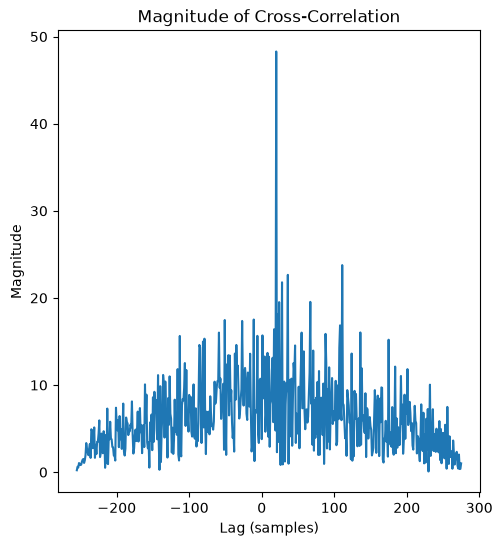

In [104]:
lag = np.arange(len(C_noisy)) - len(R) + 1
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(lag, np.abs(C_noisy))
plt.title('Magnitude of Cross-Correlation')
plt.xlabel('Lag (samples)')
plt.ylabel('Magnitude') 

# Error Probability and Mean Absolute Error

In [105]:
R = np.random.choice([-1,1], size = size)
V = (alpha * np.exp(1j * phi))*np.append(np.zeros(d), R)
power_signal = np.sum(np.abs(V)**2) / len(V)
snr = np.arange(-20, 1, 5)
error_counts = np.zeros(len(snr))
n_trials = 100

for i in range(len(snr)):
    
    sigma = np.sqrt((power_signal / (10**(snr[i]/10)))/2)
    error_count = 0
    for j in range(n_trials):
        noise = sigma*(np.random.normal(0, 1, size=V.shape) + 1j* np.random.normal(0, 1, size=V.shape))
        V_noisy = V + noise
        C_noisy = np.correlate(V_noisy, R, mode = 'full')
        e_noisy = np.argmax(np.abs(C_noisy)) - (len(R) -1)
        if e_noisy != d:
            error_count += 1       
    error_counts[i] = error_count
    print(f"SNR: {snr[i]} dB, Error count: {error_count} out of {n_trials} trials")



SNR: -20 dB, Error count: 74 out of 100 trials
SNR: -15 dB, Error count: 10 out of 100 trials
SNR: -10 dB, Error count: 0 out of 100 trials
SNR: -5 dB, Error count: 0 out of 100 trials
SNR: 0 dB, Error count: 0 out of 100 trials


SNR: -20 dB, Error count: 70 out of 100 trials
SNR: -20 dB, MAE: 32.00
SNR: -15 dB, Error count: 19 out of 100 trials
SNR: -15 dB, MAE: 7.36
SNR: -10 dB, Error count: 0 out of 100 trials
SNR: -10 dB, MAE: 0.00
SNR: -5 dB, Error count: 0 out of 100 trials
SNR: -5 dB, MAE: 0.00
SNR: 0 dB, Error count: 0 out of 100 trials
SNR: 0 dB, MAE: 0.00


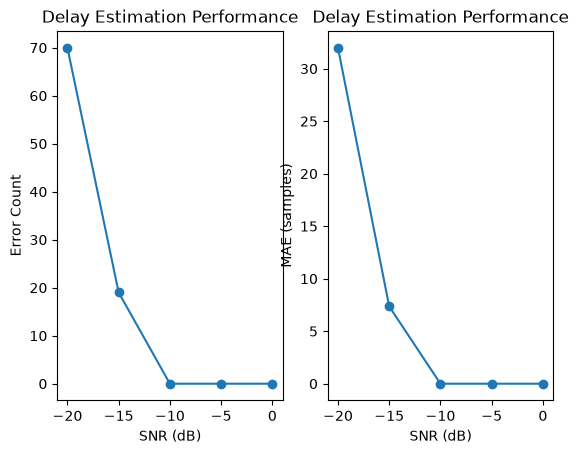

In [106]:
R = np.random.choice([-1,1], size = 256)
V = (alpha * np.exp(1j * phi))*np.append(np.zeros(d), R)
power_signal = np.sum(np.abs(V)**2) / len(V)
snr = np.arange(-20, 1, 5)
error_counts = np.zeros(len(snr))
mae = np.zeros(len(snr))
n_trials = 100
delay_errors = np.zeros([n_trials, len(snr)])
for i in range(len(snr)):
    
    sigma = np.sqrt((power_signal / (10**(snr[i]/10)))/2)
    error_count = 0
    error_sum = 0
    for j in range(n_trials):
        noise = sigma*(np.random.normal(0, 1, size=V.shape) + 1j* np.random.normal(0, 1, size=V.shape))
        V_noisy = V + noise
        C_noisy = np.correlate(V_noisy, R, mode = 'full')
        e_noisy = np.argmax(np.abs(C_noisy)) - (len(R) -1)
        if e_noisy != d:
            error_count += 1
            delay_errors[j, i] = np.abs(e_noisy - d)
            error_sum += np.abs(e_noisy - d)
    error_counts[i] = error_count
    mae[i] = error_sum / n_trials
    print(f"SNR: {snr[i]} dB, Error count: {error_count} out of {n_trials} trials")
    print(f"SNR: {snr[i]} dB, MAE: {mae[i]:.2f}")
    
plt.subplot(1, 2, 1)
plt.plot(snr, error_counts, 'o-')
plt.xlabel('SNR (dB)')
plt.ylabel('Error Count')
plt.title('Delay Estimation Performance')
plt.subplot(1, 2, 2)
plt.plot(snr, mae, 'o-')
plt.xlabel('SNR (dB)')
plt.ylabel('MAE (samples)')
plt.title('Delay Estimation Performance')
plt.show()


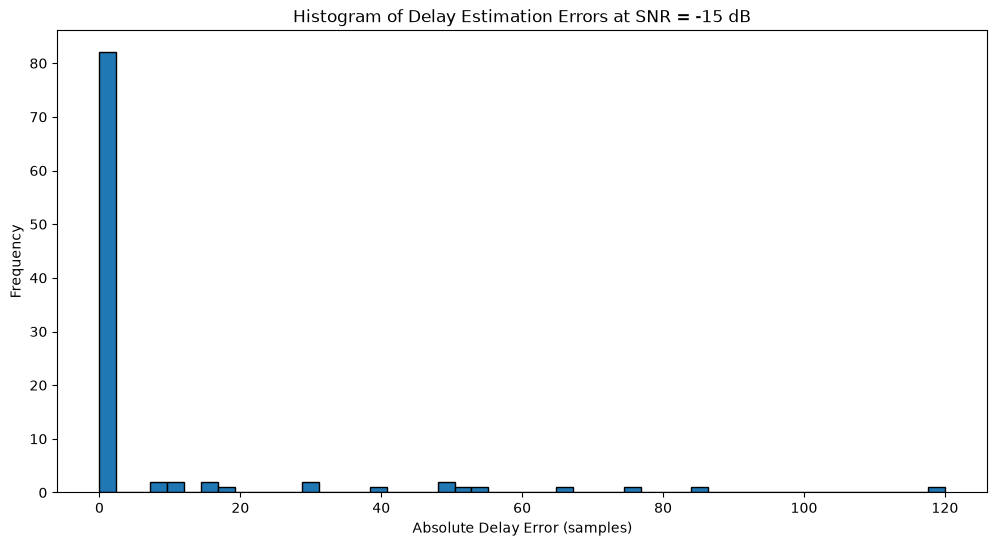

In [107]:
plt.figure(figsize=(12, 6))
plt.hist(delay_errors[:, 1], bins=50, edgecolor='black')
plt.xlabel('Absolute Delay Error (samples)')
plt.ylabel('Frequency')
plt.title('Histogram of Delay Estimation Errors at SNR = -15 dB')
plt.show()